# Renewed energy: a candidate cue for another pluck
Pitch can remain A4 while a new pluck adds energy. Compare the current 10 ms
RMS with the median RMS of FOUR preceding 10 ms blocks (40 ms total).
Advance by 2 ms. History ends exactly where the current window starts, so it
contains no current-window samples. The calculation uses no MIDI labels.

`change = current_RMS - past_median_RMS`
`positive_rise = max(0, change)` keeps increases and sets decreases to zero.
`ratio = current_RMS / past_median_RMS` says how large the rise is relative
to recent level: 2 means twice the RMS amplitude, not twice physical energy.
Raw RMS is an amplitude measure; 'energy-rise cue' is shorthand here.

Why both? Absolute rise depends on recording gain; the ratio can exaggerate
tiny changes over a near-zero baseline. Neither alone is a validated detector.
A zero baseline gives an undefined ratio (NaN), not an arbitrary huge value.
No fixed quiet period is required. These 10/2/40 ms settings are starting
choices for inspection, not optimized thresholds. No event splitting yet.

Architecture: WAV → energy measurements in attack_analysis.py → plots/tables.
Pitch estimation/filtering/grouping remain separate and unchanged. Read the
short helper to trace the four past blocks and the single current block.


In [1]:
from pathlib import Path
import csv
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from attack_analysis import measure_energy_rise
from guitartechs_midi import read_note_labels

window_seconds, hop_seconds, history_seconds = 0.010, 0.002, 0.040
view_start, view_stop = 7.8, 9.1
output_folder = Path('outputs/pitch_tracking')
output_folder.mkdir(parents=True, exist_ok=True)
real_checks = {}


## 1. Measure P1 and P2 with identical settings
Read 40 ms of extra context BEFORE the displayed interval, because the first
measurement needs history. All rows retain original-file sample indices.
Measurements are plotted at window midpoints; a row is available only after
its full 10 ms window has arrived. Peaks aren't exact attack times.


In [2]:
for player in ('P1', 'P2'):
    folder = Path.home() / 'Downloads' / f'{player}_scales'
    audio_path = folder / 'audio/directinput/directinput_C.wav'
    rate = sf.info(audio_path).samplerate
    history_samples = round(history_seconds * rate)
    origin = round(view_start * rate) - history_samples
    audio, rate = sf.read(audio_path, start=origin, stop=round(view_stop * rate))
    signal = audio[:, 0] if audio.ndim == 2 else audio
    measurements = measure_energy_rise(signal, rate, origin, window_seconds, hop_seconds, history_seconds)
    # Reference annotations enter after measurement, for inspection only.
    labels, _ = read_note_labels(folder / 'midi/midi_C.mid')
    labels = [n for n in labels if view_start <= n['start_seconds'] < view_stop]
    real_checks[player] = dict(rows=measurements, labels=labels)
    path = output_folder / f'{player}_scale_C_energy_rise_7p8-9p1s.csv'
    with path.open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(measurements[0]))
        writer.writeheader(); writer.writerows(measurements)
    print(f'{player}: {len(measurements)} measurement windows; saved {path}')
    for description, first, last in [('First A4 vicinity', 7.9, 8.1),
                                     ('Ordinary ringing comparison', 8.1, 8.35),
                                     ('Second A4 vicinity', 8.38, 8.6),
                                     ('Following G4 vicinity', 8.9, 9.08)]:
        selected = [r for r in measurements if first <= r['midpoint_seconds'] < last]
        biggest = max(selected, key=lambda r: r['positive_rise'])
        print(f"  {description}: largest RMS rise {biggest['positive_rise']:.6f} at "
              f"{biggest['midpoint_seconds']:.3f}s; current {biggest['current_rms']:.6f}, "
              f"history {biggest['past_median_rms']:.6f}, ratio {biggest['rms_ratio']:.2f}")
print('These are maxima within reviewed intervals, NOT automatically detected attacks.')


P1: 646 measurement windows; saved outputs/pitch_tracking/P1_scale_C_energy_rise_7p8-9p1s.csv
  First A4 vicinity: largest RMS rise 0.037464 at 7.997s; current 0.038558, history 0.001094, ratio 35.25
  Ordinary ringing comparison: largest RMS rise 0.000487 at 8.313s; current 0.019699, history 0.019212, ratio 1.03
  Second A4 vicinity: largest RMS rise 0.040869 at 8.491s; current 0.041790, history 0.000921, ratio 45.37
  Following G4 vicinity: largest RMS rise 0.033055 at 8.975s; current 0.033507, history 0.000452, ratio 74.12
P2: 646 measurement windows; saved outputs/pitch_tracking/P2_scale_C_energy_rise_7p8-9p1s.csv
  First A4 vicinity: largest RMS rise 0.010672 at 7.991s; current 0.012494, history 0.001822, ratio 6.86
  Ordinary ringing comparison: largest RMS rise 0.000229 at 8.139s; current 0.010715, history 0.010486, ratio 1.02
  Second A4 vicinity: largest RMS rise 0.021983 at 8.471s; current 0.022798, history 0.000815, ratio 27.99
  Following G4 vicinity: largest RMS rise 0.011

## 2. Read the energy-rise curves
Top: blue current RMS versus orange recent baseline. Middle: positive rise
above that baseline. Bottom: ratio; 1 means equal level. Dashed vertical lines
are original MIDI starts, including the following G4; no alignment correction.
Gray shaded interval is ordinary ringing for comparison. Note the small
fluctuations there: a positive rise doesn't automatically mean a new pluck.
One attack may produce several bumps, so don't count every peak as a note.


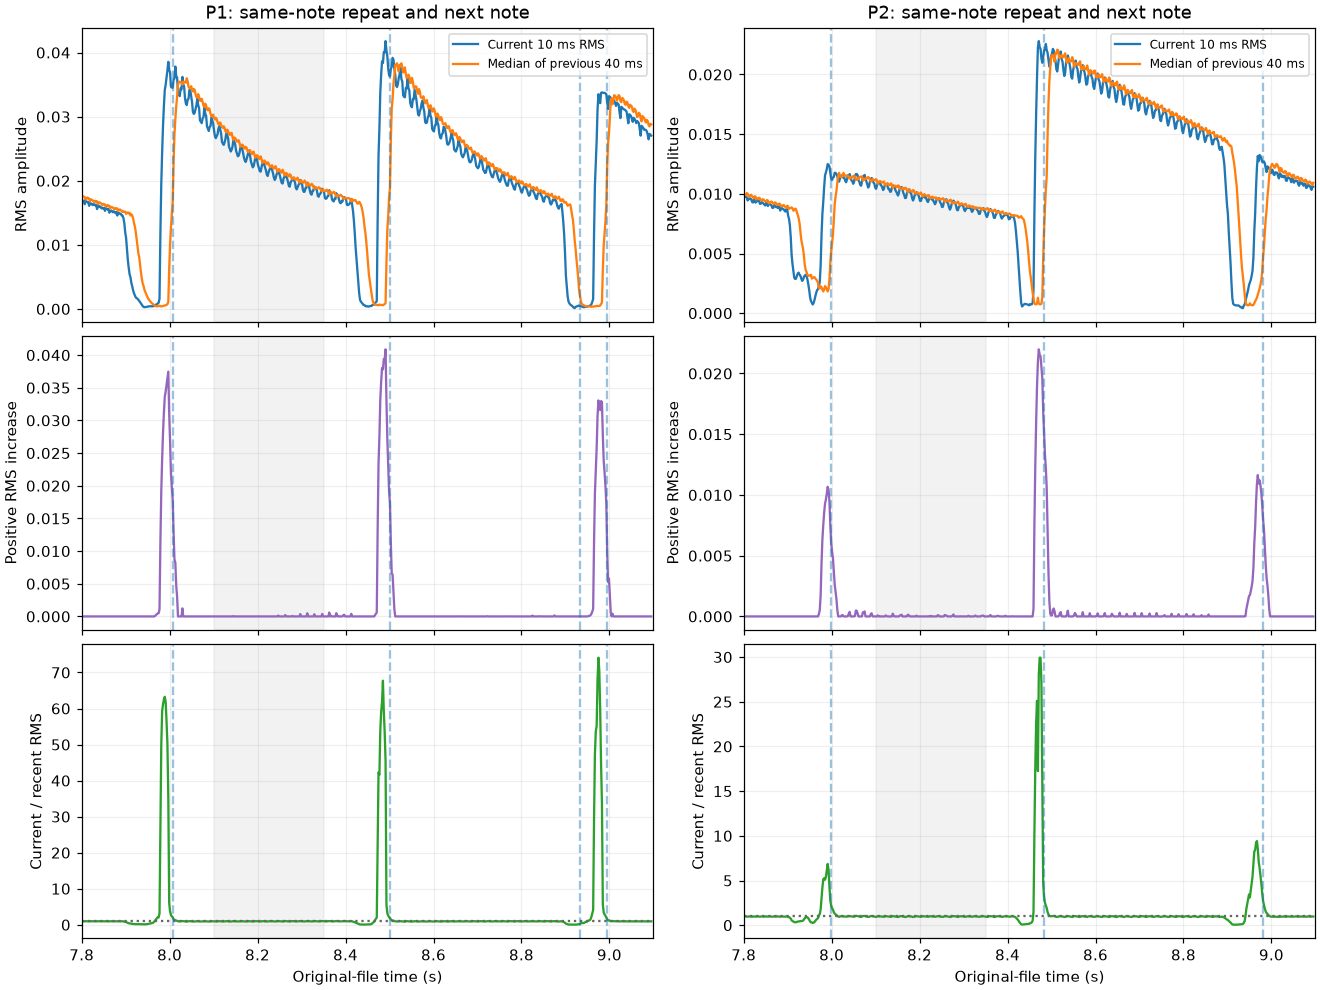

In [3]:
real_fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True, constrained_layout=True)
for column, (player, result) in enumerate(real_checks.items()):
    rows = result['rows']
    times = np.array([r['midpoint_seconds'] for r in rows])
    axes[0, column].plot(times, [r['current_rms'] for r in rows], label='Current 10 ms RMS')
    axes[0, column].plot(times, [r['past_median_rms'] for r in rows], label='Median of previous 40 ms')
    axes[0, column].set(title=f'{player}: same-note repeat and next note', ylabel='RMS amplitude')
    axes[0, column].legend(fontsize=8)
    axes[1, column].plot(times, [r['positive_rise'] for r in rows], color='tab:purple')
    axes[1, column].set(ylabel='Positive RMS increase')
    axes[2, column].plot(times, [r['rms_ratio'] for r in rows], color='tab:green')
    axes[2, column].axhline(1, linestyle=':', color='0.4')
    axes[2, column].set(ylabel='Current / recent RMS', xlabel='Original-file time (s)')
    for ax in axes[:, column]:
        ax.set_xlim(view_start, view_stop)
        ax.axvspan(8.1, 8.35, color='0.5', alpha=0.1)
        ax.grid(alpha=0.2)
        for note in result['labels']:
            ax.axvline(note['start_seconds'], linestyle='--', color='tab:blue', alpha=0.45)
real_fig.savefig(output_folder / 'P1_P2_repeated_A4_energy_rise.png', dpi=150)
plt.show()


## 3. Controlled example: add energy while the same pitch keeps ringing
The real A4 recordings include a dip before the repeat. To test the intended
mechanism WITHOUT relying on that dip, construct an illustrative 440 Hz tone.
It decays continuously, then a second 440 Hz excitation starts at 0.7 s with
a 5 ms ramp. The original ringing is never muted. Compare to the same decaying
tone with no second excitation, using exactly the same measurement settings.

This deliberately simple example adds the waves in phase. It is not a guitar
recording or validation of real repeated picking. Real strings can be damped
or change phase/timbre, and another pluck might not increase RMS clearly.
A weak energy rise may eventually need another cue, such as spectral change.


Old ringing only: largest rise near 0.7s = 0.000000; baseline 0.049698; ratio 0.97
New excitation over old ringing: largest rise near 0.7s = 0.055907; baseline 0.049037; ratio 2.14


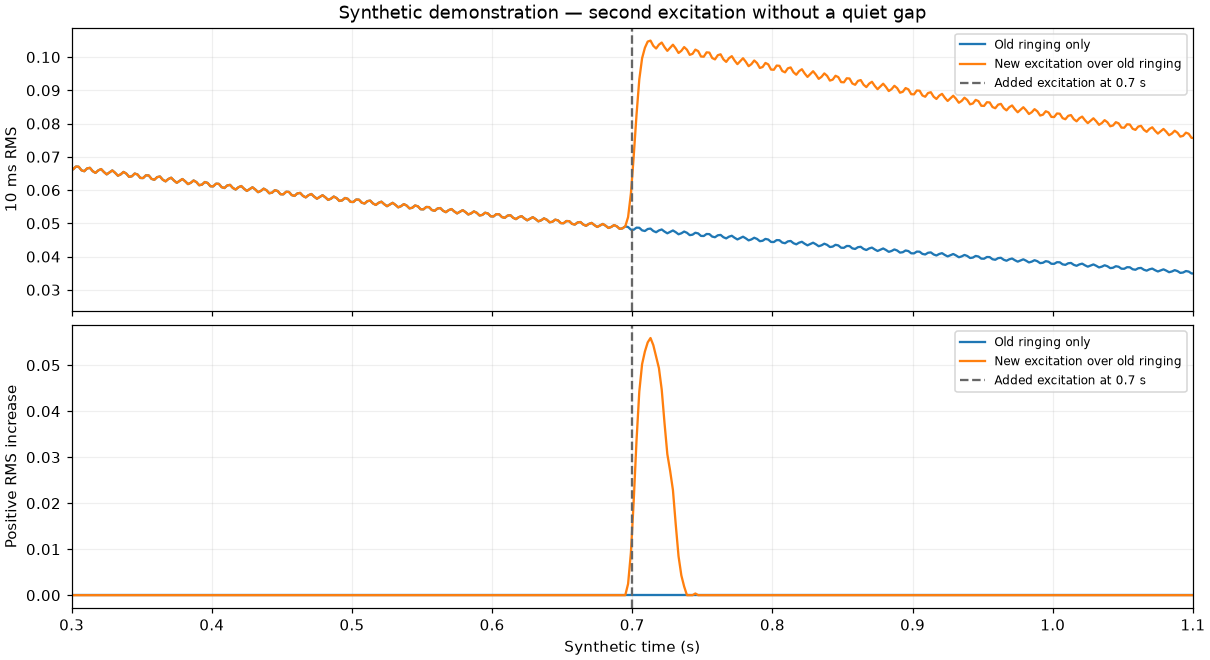

In [4]:
synthetic_rate = 48000
synthetic_time = np.arange(round(1.4 * synthetic_rate)) / synthetic_rate
old_envelope = 0.12 * np.exp(-0.8 * synthetic_time)
carrier = np.sin(2 * np.pi * 440 * synthetic_time)
old_ringing = old_envelope * carrier
excitation_time = 0.7
since_excitation = np.maximum(synthetic_time - excitation_time, 0)
new_envelope = 0.08 * np.clip((synthetic_time - excitation_time) / 0.005, 0, 1) * np.exp(-0.8 * since_excitation)
renewed_ringing = old_ringing + new_envelope * carrier
synthetic_cases = {'Old ringing only': old_ringing, 'New excitation over old ringing': renewed_ringing}
synthetic_fig, synthetic_axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
synthetic_results = {}
for description, signal in synthetic_cases.items():
    measured = measure_energy_rise(signal, synthetic_rate, 0, window_seconds, hop_seconds, history_seconds)
    synthetic_results[description] = measured
    times = np.array([r['midpoint_seconds'] for r in measured])
    synthetic_axes[0].plot(times, [r['current_rms'] for r in measured], label=description)
    synthetic_axes[1].plot(times, [r['positive_rise'] for r in measured], label=description)
    around_second = [r for r in measured if 0.7 <= r['midpoint_seconds'] <= 0.76]
    biggest = max(around_second, key=lambda r: r['positive_rise'])
    print(f"{description}: largest rise near 0.7s = {biggest['positive_rise']:.6f}; "
          f"baseline {biggest['past_median_rms']:.6f}; ratio {biggest['rms_ratio']:.2f}")
synthetic_axes[0].set(title='Synthetic demonstration — second excitation without a quiet gap', ylabel='10 ms RMS')
synthetic_axes[1].set(ylabel='Positive RMS increase', xlabel='Synthetic time (s)')
for ax in synthetic_axes:
    ax.axvline(excitation_time, linestyle='--', color='0.4', label='Added excitation at 0.7 s')
    ax.set_xlim(0.3, 1.1)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
synthetic_fig.savefig(output_folder / 'synthetic_renewed_A4_energy_rise.png', dpi=150)
plt.show()


## What comes next
First compare real rises with ordinary ringing and the no-gap illustration.
Then choose an explicit candidate rule that considers both level and increase,
plus a short separation rule to avoid counting one pluck several times.
Don't require prior silence: the recent baseline can be nonzero.
Fast picking, natural amplitude modulation and very quiet re-picking will test
that rule. Only after reviewing candidate attacks should they split note groups.
No threshold, automatic attack list or note-event changes were added here.
